# Guided Inference 4

Scattering with a wall



# Ground Truths

In [1]:
_GT_DR_  = 0.25
_GT_V_   = 1.
_GT_ALPHA_ = 1. # Wall scattering strength
_GT_WALL_X_ = 2. # Location of the walls
_DT_OBS_ = 1.0
_DT_     = 0.1
_N_OBS_  = 50
_SIG_OBS_ = 5e-6
_FUTURES_ = 8

# Imports

In [2]:
from numba import njit, prange
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import Tensor as T
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions.normal import Normal
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
from itertools import zip_longest
from ppolib import PPO_Agent
import pickle
import os
from matplotlib.colors import Normalize
from matplotlib.collections import LineCollection

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from scipy.stats import binned_statistic_2d
from scipy.ndimage import zoom, gaussian_filter, gaussian_filter1d
from tqdm.notebook import tqdm
from random import choice
from inference_tools_ppo import ParticleFilter, crng, HilbertSorter, ConditionedBridge, bridge_logl, ZeroBasedRNG, effective_sample_size
from matplotlib import patches as mpatches
import matplotlib as mpl
from matplotlib import cm as cm

sorter = HilbertSorter(depth=9, dims=2)
bridge_gen = ConditionedBridge()

torch.autograd.set_detect_anomaly(True)

# SDE Equation of Motion

In [3]:
def abp_sde(T0, T1, X0, params):
    
    output_hires = params.get('output_hires', False)
    omit_bridges = params.get('omit_bridges', False)
    use_tqdm = params.get('use_tqdm', False)
    target_shift_P = params.get('target_shift_PHI', 0.)
    target_slope_P = params.get('target_slope_PHI', 0.) # TODO Set to .05 for testing, should not matter anywhere
    offset_shift_P = params.get('offset_shift_PHI', 0.)
    offset_slope_P = params.get('offset_slope_PHI', 0.)
    spread = params.get('bridge_spread_rate', 0)
    BridgeGen = params['BridgeGen']
    RNG = params['RNG']
    logDr = params['logDr']
    logv  = params['logv']
    logAlpha  = params['logAlpha']
    Dr    = np.exp(logDr)
    v     = np.exp(logv)
    Alpha     = np.exp(logAlpha)
    _id = params.get('id', -1)
    dt  = params['dt']
    x_wall = params['x_wall']
    
    X = X0.copy()
    T = T0
    step = 0
    
    if output_hires:
        hires  = [X.copy()]
        hiresT = [T]
        
    n_steps = int((T1 - T0) / dt + 1)
    n_parts = X.shape[0]
    dt_ = (T1 - T0) / n_steps
    
    if not omit_bridges:
        
        slope_factor = 1 / (np.sqrt(2 * Dr * dt_))
        shift_factor = 1 / (np.sqrt(2 * Dr * dt_) * v * dt_)
        
        slopeP = (target_slope_P + spread * np.random.randn(n_parts)) * np.ones((n_parts,)) * slope_factor + offset_slope_P
        shiftP = (target_shift_P + spread * np.random.randn(n_parts)) * np.ones((n_parts,)) * shift_factor + offset_shift_P
        
        bridge_res_P = BridgeGen.get(n_steps + 1, shiftP, slopeP, ('abpsdePbridgegen', _id, T0, T1), 0.0, RNG)
        
        #logl = - np.mean((slopeP/bridge_res_P['std1'])**2) / 2 - np.mean((shiftP/bridge_res_P['std2'])**2) / 2# - np.log(2 * np.pi * bridge_res_P['std1']**2) / 2 - np.log(2 * np.pi * bridge_res_P['std2']**2) / 2  # + np.log(slope_factor) + np.log(shift_factor)
        #logl *= 1

        logl = bridge_logl(np.mean(shiftP), np.mean(slopeP), n_steps + 1) # + np.log(slope_factor) + np.log(shift_factor)
        #logl *= 0
        
        wP  = bridge_res_P['w']
        dwP = np.diff(wP, axis=0)
        dwP = np.concatenate([wP[[0],:], dwP])
        ddP = np.diff(dwP, axis=0).T

        w = ddP
        
    else:
        w = RNG.get(('abpsde_full', _id, T0, T1), (n_parts, n_steps), corr=0)
        logl = 0

    if use_tqdm:  
        R_ = tqdm(range(n_steps))
    else:
        R_ = range(n_steps)
        
    for k in R_:

        ''' Integrate the EOM '''

        dx = np.cos(X[:, 2])
        dy = np.sin(X[:, 2])
        torque = -dy * 0 #  * np.sin((T0 + k * dt) / 6) + dy * B * np.cos((T0 + k * dt) / 6)
        drift = np.stack([dx*v, dy*v, torque], axis=1)

        X[..., -1] += np.sqrt(dt_) * w[..., k] * np.sqrt(2 * Dr)
        X += dt_ * drift

        X[:, 2] = np.mod(X[:, 2], 2 * np.pi)

        # Reflect particles at the walls
        # Right Wall
        passed_wall = X[:, 0] > x_wall
        X[passed_wall, 0] = 2 * x_wall - X[passed_wall, 0]

        dx = np.cos(X[passed_wall, 2])
        dy = np.sin(X[passed_wall, 2])

        dx_soft = dx * 0
        dx_bounce = -dx
        dx_actual = Alpha * dx_bounce + (1 - Alpha) * dx_soft
        X[passed_wall, 2] = np.arctan2(dy, dx_actual)
        
        
        # Left Wall
        passed_wall = X[:, 0] < -x_wall
        X[passed_wall, 0] = -2 * x_wall - X[passed_wall, 0]

        dx = np.cos(X[passed_wall, 2])
        dy = np.sin(X[passed_wall, 2])

        dx_soft = dx * 0
        dx_bounce = -dx
        dx_actual = Alpha * dx_bounce + (1 - Alpha) * dx_soft
        X[passed_wall, 2] = np.arctan2(dy, dx_actual)
        
        #l  # Reset position to the wall boundary
        #X[passed_wall, 2] = np.pi - X[passed_wall, 2]  # Reflect angle

        
        if output_hires:
            hires.append(X.copy())
            hiresT.append(T)
    
    res_dict = dict(X1=X, logl=logl)
    
    if output_hires:
        res_dict['per_particle_streams'] = dict(hires=np.stack(hires, -1))

    return res_dict

# Data Generation

Generating the test data, with perfectly straight movement

In [4]:
def abp_run_simple(X0=np.zeros((1, 3)),
                   dt=1e-1, Tout=np.linspace(0, 1, 11),
                   params=None
                  ):   
    
    if params is None:
        params = dict(RNG=crng(),
                      Dr = 1e-2,
                      v = 1,
                      dt = dt,
                      output_hires=True,
                      BridgeGen=bridge_gen,
                      omit_bridges=True,
                      use_tqdm = False,
                     )

    x = [X0[:, 0]]
    y = [X0[:, 1]]
    phi = [X0[:, 2]]
    Told = 0
    for Tmax in Tout:
        params['RNG'].reroll(0)
        sim_res = abp_sde(Told, Tmax, np.stack([x[-1], y[-1], phi[-1]]).T, params)
        Told = Tmax
        x.append(sim_res['X1'][:, 0])
        y.append(sim_res['X1'][:, 1])
        phi.append(sim_res['X1'][:, 2])

    x = np.stack(x[1:])
    y = np.stack(y[1:])
    
    return dict(x=x, y=y)

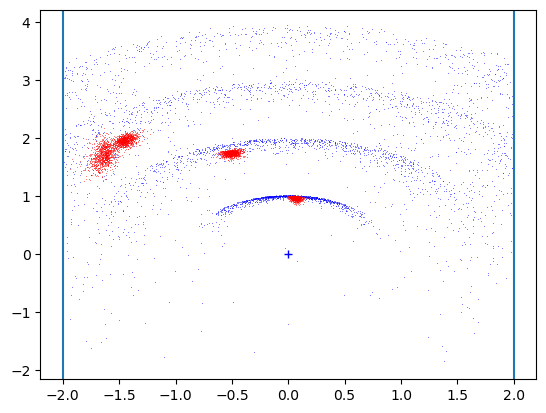

In [5]:
N = 1000
dt = _DT_
v = _GT_V_
Nobs_test = 4
Tmax = _DT_OBS_ * (Nobs_test)

X0 = np.random.uniform(size=(N,3)) * [0, 0, 0]
X0[:, -1] = np.pi/2
Tout=np.linspace(_DT_OBS_, Tmax, Nobs_test)

''' -------------------------------------------------- '''

params = dict(RNG=crng(seed=1234),
              logDr = np.log(_GT_DR_),
              logv = np.log(_GT_V_),
              logAlpha = np.log(_GT_ALPHA_),
              dt = dt,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
              use_tqdm = False,
              target_slope_PHI=0.7,
              target_shift_PHI=0.,
              x_wall = _GT_WALL_X_,
             )

res = abp_run_simple(X0, dt, Tout, params)
GT_X = res['x']
GT_Y = res['y']
plt.plot(GT_X, GT_Y, ',b', alpha=0.5)

''' -------------------------------------------------- '''

params['omit_bridges'] = False
params['bridge_spread_rate'] = 0.03
res = abp_run_simple(X0, dt, Tout, params)
GT_X = res['x']
GT_Y = res['y']
plt.plot(GT_X, GT_Y, ',r', alpha=0.5)

''' -------------------------------------------------- '''


plt.plot([0], [0], '+b')
#plt.gca().axis('equal')
plt.axvline(params['x_wall'])
plt.axvline(-params['x_wall'])
plt.show()

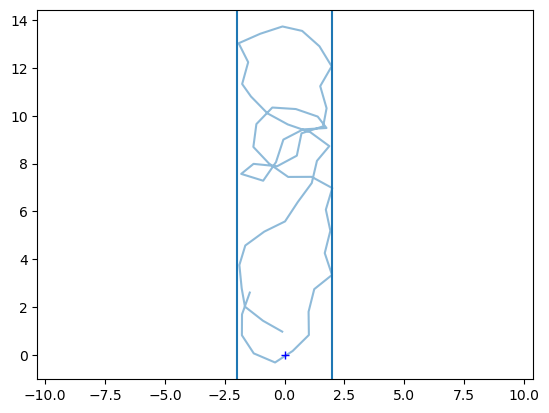

In [6]:
N = 1
dt = _DT_
v = _GT_V_
Tmax = _DT_OBS_ * (_N_OBS_ + _FUTURES_ + 1)

X0 = np.random.uniform(size=(N,3)) * [0, 0, 0]
X0[:, -1] = np.pi/2
Tout=np.linspace(_DT_OBS_, Tmax, _N_OBS_ + _FUTURES_ + 1)

params = dict(RNG=crng(seed=123),
              logDr = np.log(_GT_DR_),
              logv = np.log(_GT_V_),
              logAlpha = np.log(_GT_ALPHA_),
              dt = dt,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
              use_tqdm = False,
              target_slope_PHI=0,
              target_shift_PHI=0.,
              x_wall = _GT_WALL_X_
             )

res = abp_run_simple(X0, dt, Tout, params)
GT_X = res['x']
GT_Y = res['y']
OBS_X = GT_X + np.random.normal(scale = _SIG_OBS_, size=GT_X.shape)
OBS_Y = GT_Y + np.random.normal(scale = _SIG_OBS_, size=GT_Y.shape)

plt.plot(GT_X, GT_Y, '-', alpha=0.5)
#plt.plot(OBS_X, OBS_Y, 'xr', alpha=0.5)
plt.plot([0], [0], '+b')
plt.gca().axis('equal')
plt.axvline(params['x_wall'])
plt.axvline(-params['x_wall'])
plt.show()

# Training the Guide

In [7]:
params = dict(RNG=crng(),
              logDr = np.log(_GT_DR_*1.),
              logv = np.log(_GT_V_*1.),
              dt = _DT_,
              HilbertSort_dims = (0,1),
              HilbertSorter = sorter,
              sigma_observation = _SIG_OBS_,
              output_hires=False,
              output_trajectory=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              HilbertSort_useObservationCenter = False,
              observation_parameters = [],
              reward_range = 1e-10,
              action_range0 = 1.0,
              action_range1 = 1.0,
              bridge_spread_rate = 0.002,
              deterministic_agent = False,
              provide_absolute_orientation = True,
              provide_absolute_x_location = True,
              provide_absolute_y_location = True,
              provide_swarm_polarity = True,
              x_wall = _GT_WALL_X_,
             )

def abp_logl(X, Y, params):
    sigma = params['sigma_observation']
    return np.nansum( -0.5*((X - Y) / sigma) ** 2, axis=1)

In [8]:
Y0 = [dict(T=T,
           Y=np.array([float(X[0]), float(Y[0]), np.nan]),
           #targ_x = float(X[0]),
           #targ_y = float(Y[0]),
           #targ_dx = 1,
           #targ_dy = 0,
          )
      for T, X, Y in zip(Tout, OBS_X, OBS_Y)
     ]

# Augment each observation with the offsets to future target points

futures = _FUTURES_


for y in Y0:
    y['future_x'] = [y['Y'][0]]
    y['future_y'] = [y['Y'][1]]
    
for offset in range(1, futures + 1):    
    for y1, y2 in zip(Y0, Y0[offset:]):
        y1['future_x'].append(y2['Y'][0])
        y1['future_y'].append(y2['Y'][1])

params['futures'] = futures
Y0 = Y0[:_N_OBS_] # Cut of the last observations that don't have enough futures

In [9]:
fresh_agent = True
train_agent = True
agent_name = "Guide4Scatter"

lr = 2e-4
hidden_layer_size = 64


if fresh_agent:
    Agent = PPO_Agent(2 * futures + 9, 2,
                      learning_rate=lr,
                      hidden_layer_size=hidden_layer_size,
                      #tensorboard_suffix=f'f{futures}_h{hidden_layer_size}_lr_{lr}',
                      #name=agent_name,
                     )
    Agent.delete_tensorboard_data()
    Agent.gamma = 0.5
else:
    Agent = PPO_Agent.load(f"agents/{agent_name}")


params['Agent'] = Agent
Agent.name = agent_name
relaxation_max = 0.25
relaxation = relaxation_max / _SIG_OBS_
total_steps = 0

No TensorBoard data found at runs/20241129-082752.


In [10]:
#relaxation = 1000

  0%|          | 0/4000 [00:00<?, ?it/s]

Bye!


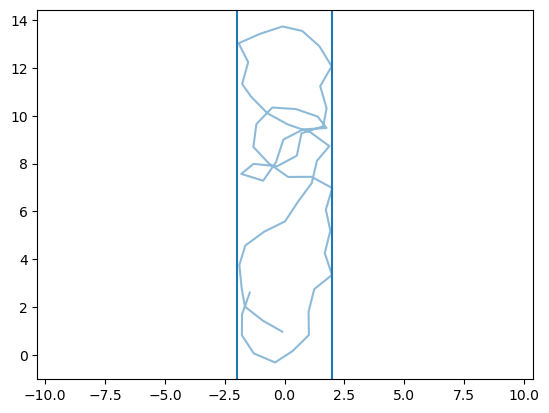

In [29]:
N_parts = 2500
Agent.start_tensorboard_writer()
Agent.recording = False
Agent.awaiting_reward = False
params['deterministic_agent'] = False
params['bridge_spread_rate'] = 0.0
params['reward_range'] = 1e-25,
params['RNG'] = crng()

Agent.ent_coef = 0.000001

X0 = (np.zeros((N_parts, 3)))
X0[:, -1] = np.pi/2

len_run = []
rew_run = []
logl_run = []
sde_aux_logl_run = []
action0_run = []
action1_run = []

n_training_steps_decay = 4000
n_training_steps_constant = 0
relaxation_schedule = np.concatenate((np.logspace(np.log10(1. / _SIG_OBS_), np.log10(1), n_training_steps_decay), [1.0] * n_training_steps_constant))

lr_schedule = [lr] * n_training_steps_decay + [lr/1] * n_training_steps_constant

Alpha_offset_min = 0.9
Alpha_offset_max = 1.1


relaxation_adoption = 0.9995
relaxation_recovery = 0.9995

if train_agent:    
    for i, _ in tqdm(enumerate(relaxation_schedule), total=len(relaxation_schedule)):
        try:
            #params['sigma_observation'] = _SIG_OBS_ * relaxation_schedule[i]
            params['sigma_observation'] = _SIG_OBS_ * relaxation
            for _ in (range(1)):
                Agent.start_recording()
                while len(Agent.obs) < 1024:
                    Alpha_offset = np.random.uniform(Alpha_offset_min, Alpha_offset_max)
                    params['use_bridge_offsets'] = False
                    params['logAlpha'] = np.log(_GT_ALPHA_ * Alpha_offset)
                    params['additional_agent_information'] = [Alpha_offset, ]
                    params['RNG'].reroll()
                    res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
                    length = res['trajectory'].shape[1]
                    
                    if length >= _N_OBS_:
                    #if res['min_diversity'] > 0.35:
                        relaxation *= relaxation_adoption
                        if relaxation < 1.0:
                            relaxation = 1.0
                    #else:
                    #    relaxation /= relaxation_recovery
                    #    if relaxation >= relaxation_max / _SIG_OBS_:
                    #        relaxation = relaxation_max / _SIG_OBS_
                            
                    len_run.append([Alpha_offset, length])
                    rew_run.append([Alpha_offset, res['total_reward_collected']])
                    logl_run.append([Alpha_offset, res['logl']])
                    action0_run.append([Alpha_offset, res['action0_stress']])
                    action1_run.append([Alpha_offset, res['action1_stress']])
                    sde_aux_logl_run.append([Alpha_offset, res['sde_aux_logl']])

                if relaxation < 5.0:
                    Agent.optimizer.param_groups[0]["lr"] = lr / 1
                else:
                    Agent.optimizer.param_groups[0]["lr"] = lr / 1
                    
                Agent.learn(minibatch_size=16, epochs=3)
                
                Agent.report_telemetry("target_precision", relaxation * _SIG_OBS_)
                Agent.report_telemetry("swarm_diversity", res['mean_diversity'])
                Agent.report_telemetry("swarm_diversity_min", res['min_diversity'])
                Agent.report_telemetry("swarm_particles_min", int(N_parts * res['min_diversity']))
                Agent.report_telemetry("action0_stress", res['action0_stress'])
                Agent.report_telemetry("action0_stress_max", res['action0_stress_max'])
                Agent.report_telemetry("action1_stress", res['action1_stress'])
                Agent.report_telemetry("action1_stress_max", res['action1_stress_max'])
                Agent.stop_recording()
            #plt.plot(res['trajectory'][0,:], res['trajectory'][1,:], lw=2, ls='-', c='k')
            #plt.plot(GT_X, GT_Y, '-', alpha=0.5)
            #end_ = min(length+10, len(GT_X))
            #plt.plot(GT_X[length-1: end_], GT_Y[length-1:end_], '--r', alpha=0.5)
            #plt.plot(OBS_X, OBS_Y, 'xr', alpha=0.5)
            #plt.gca().axis('equal')
            #zoom_out = 5
            #plt.xlim((OBS_X.min()-zoom_out, OBS_X.max()+zoom_out))
            #plt.ylim((OBS_Y.min()-zoom_out, OBS_Y.max()+zoom_out))

            plt.figure(figsize=(14, 5))
            plt.subplot(1, 3, 1)
            plt.plot(GT_X, range(len(GT_X)), '-b', alpha=0.5,)
            plt.plot(res['trajectory'][0,:], range(len(res['trajectory'][0,:])), 'k', lw=2)
            #plt.gca().invert_yaxis()
            plt.xlabel("x")
            plt.ylabel("t")

            plt.subplot(1, 3, 2)
            plt.plot(GT_Y, '-b', alpha=0.5,)
            plt.plot(res['trajectory'][1,:], 'k', lw=2)
            plt.title("Y")
            plt.xlabel("t")
            plt.ylabel("y")

            plt.subplot(1, 3, 3)

            x = res['trajectory'][0, :]
            y = res['trajectory'][1, :]
            
            # Create segments for coloring
            points = np.array([x, y]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]], axis=1)
            
            # Create a LineCollection
            norm = Normalize(0, len(x) - 1)  # Normalize color from start to end
            lc = LineCollection(segments, cmap='viridis', norm=norm)
            lc.set_array(np.linspace(0, len(x) - 1, len(x)))  # Map segment indices to color
            lc.set_linewidth(2)  # Set the width of the line
            
            plt.gca().add_collection(lc)

            zoom_out = 2

            plt.axvline(params["x_wall"], c='k', ls='--')
            plt.axvline(-params["x_wall"], c='k', ls='--')
            #plt.plot(GT_X, GT_Y, '-b')
            #plt.plot(res['trajectory'][0,:], res['trajectory'][1,:], 'k')
            plt.xlim((OBS_X.min()-zoom_out, OBS_X.max()+zoom_out))
            plt.ylim((OBS_Y.min()-zoom_out, OBS_Y.max()+zoom_out))
            
            plt.suptitle(f"{Agent.episode_count} episodes seen")
            plt.savefig(f"img_11/{agent_name}_{total_steps}.png")
            total_steps += 1
            plt.close()
        except KeyboardInterrupt:
            print("Bye!")
            break
    
    plt.plot(res['trajectory'][0,:], res['trajectory'][1,:], lw=2, ls='-', c='k')
    plt.plot(GT_X, GT_Y, '-', alpha=0.5)
    plt.gca().axis('equal')
    plt.axvline(params['x_wall'])
    plt.axvline(-params['x_wall'])
    #plt.plot(OBS_X, OBS_Y, 'xr', alpha=0.5)
    #plt.plot([0], [0], '+b')


In [12]:
if fresh_agent:
    Agent.save_model()

State saved to agents/Guide4Scatter.


In [13]:
relaxation

25730.853160093553

In [14]:
np.array(len_run).shape

(7132, 2)

(array([644., 700., 658., 646., 618., 631., 662., 631., 673., 605.]),
 array([0.90005365, 0.92004705, 0.94004045, 0.96003386, 0.98002726,
        1.00002067, 1.02001407, 1.04000747, 1.06000088, 1.07999428,
        1.09998769]),
 <BarContainer object of 10 artists>)

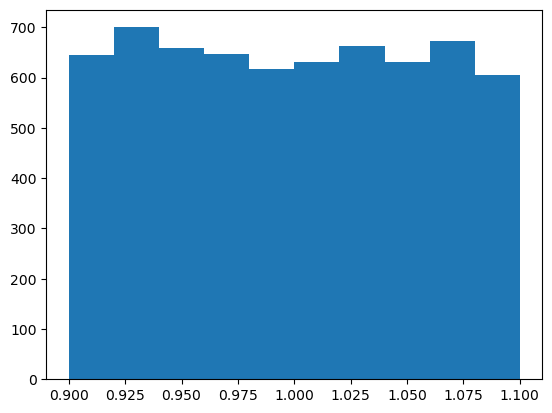

In [15]:
Alpha_ = np.array(len_run)[:,0]
len_   = np.array(len_run)[:,1]
plt.hist(Alpha_[len_ < _N_OBS_])

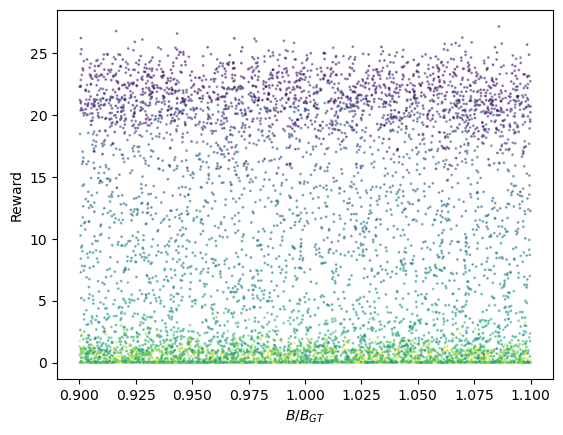

In [16]:
if train_agent:
    colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
    plt.scatter(*np.array(rew_run).T, c=colors, s=1, alpha=0.51)
    plt.xlabel(r"$B/B_{GT}$")
    plt.ylabel("Reward")
    plt.savefig("g3_img/reward.png", dpi=300)
    plt.show()

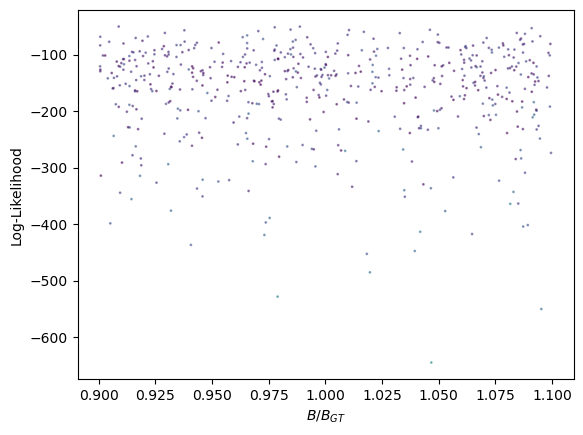

In [17]:
if train_agent:
    colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
    plt.scatter(*np.array(logl_run).T, c=colors, s=1, alpha=0.51)
    plt.xlabel(r"$B/B_{GT}$")
    plt.ylabel("Log-Likelihood")
    plt.savefig("g3_img/logl.png", dpi=300)
    plt.show()

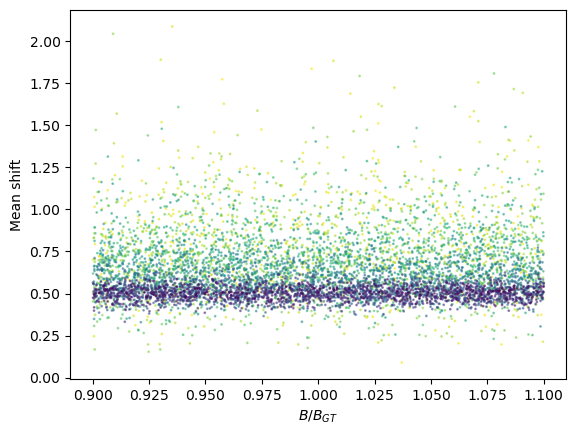

In [18]:
if train_agent:
    colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
    plt.scatter(*np.array(action0_run).T, c=colors, s=1, alpha=0.51)
    plt.xlabel(r"$B/B_{GT}$")
    plt.ylabel("Mean shift")
    plt.savefig("g3_img/shift.png", dpi=300)
    plt.show()

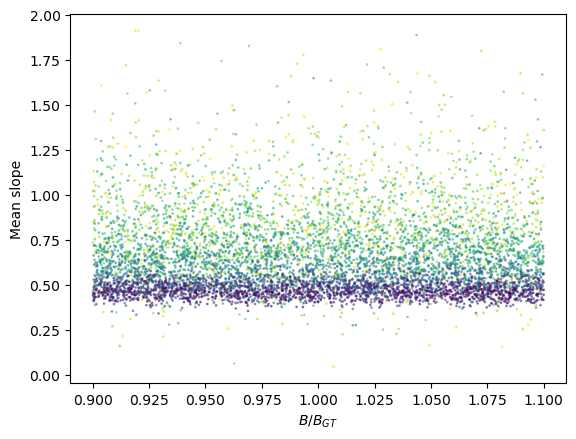

In [19]:
if train_agent:
    colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
    plt.scatter(*np.array(action1_run).T, c=colors, s=1, alpha=0.51)
    plt.xlabel(r"$B/B_{GT}$")
    plt.ylabel("Mean slope")
    plt.savefig("g3_img/slope.png", dpi=300)
    plt.show()

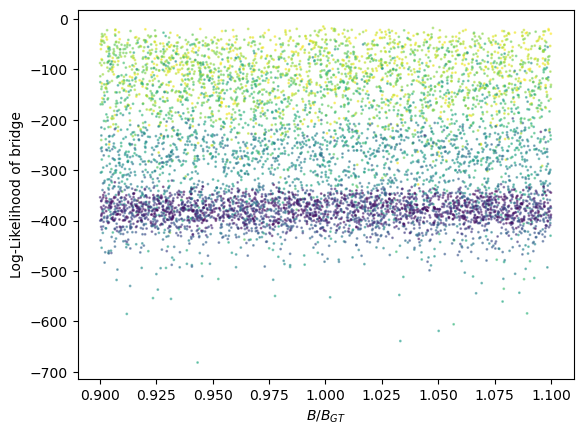

In [20]:
if train_agent:
    colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
    plt.scatter(*np.array(sde_aux_logl_run).T, c=colors, s=1, alpha=0.51)
    plt.xlabel(r"$B/B_{GT}$")
    plt.ylabel("Log-Likelihood of bridge")
    plt.savefig("g3_img/bridge_logl.png", dpi=300)
    plt.show()

# Check Agent Performance

# Without Bridge

In [21]:
relaxation = 1.0

In [22]:
Agent.recording = False
Agent.awaiting_reward = False

X0 = (np.zeros((7500, 3)))
X0[:, -1] = np.pi/2

len_test = []
rew_test = []
logl_test = []

#relaxation = 5

Alpha_offsets = np.linspace(Alpha_offset_min, Alpha_offset_max, 50)

for Alpha_off in tqdm(Alpha_offsets):
        params['sigma_observation'] = relaxation * _SIG_OBS_ * 1000
        params['logv'] = np.log(_GT_V_)
        params['logAlpha'] = np.log(_GT_ALPHA_ * Alpha_off)
        params['additional_agent_information'] = [Alpha_off, ]
        params['deterministic_agent'] = True
        params['RNG'].reroll()
        params['omit_bridges'] = True
        params['use_bridge_offsets'] = False
        res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
        length = res['trajectory'].shape[1]
        len_test.append(length)
        rew_test.append([Alpha_off, res['total_reward_collected']])
        logl_test.append([Alpha_off, res['logl']])
            

  0%|          | 0/50 [00:00<?, ?it/s]

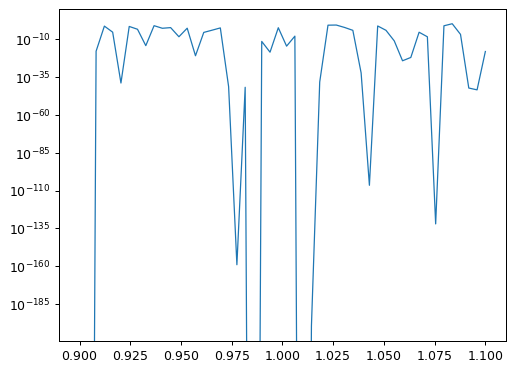

In [23]:
voff_ = np.array(logl_test)[:, 0]
logl_ = np.array(logl_test)[:, 1]

logl_ -= logl_.max()
lklhd_ = np.exp(logl_)


plt.figure(dpi=90)
plt.semilogy(voff_, lklhd_, alpha=1, label="Naive Particle Filter", lw=1)
#plt.ylim([1e-25, 1e3])

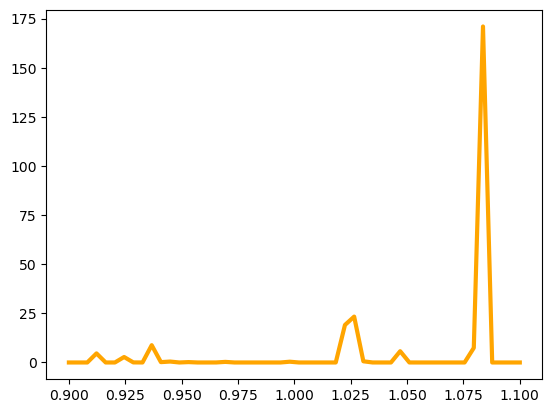

In [24]:
plt.plot(voff_, lklhd_ / np.trapz(lklhd_, voff_), alpha=1, label="Naive Particle Filter", lw=3, c='orange')

# With Bridge

In [25]:
Agent.recording = False
Agent.awaiting_reward = False

#params['offsetRNG'] = ZeroBasedRNG()


params['RNG'] = crng()

len_test_Alpha = []
rew_test_Alpha = []
logl_test_Alpha = []


Alpha_offsets = np.linspace(Alpha_offset_min, Alpha_offset_max, 50)

for Alpha_off in tqdm(Alpha_offsets):
        params['sigma_observation'] = relaxation * _SIG_OBS_ * 1000
        params['logv'] = np.log(_GT_V_)
        params['logAlpha'] = np.log(_GT_ALPHA_ * Alpha_off)
        params['additional_agent_information'] = [Alpha_off, ]
        params['deterministic_agent'] = True
        params['use_bridge_offsets'] = False
        params['RNG'].reroll()
        params['omit_bridges'] = False
        params['offset_shift_PHI'] = 0.
        params['offset_slope_PHI'] = 0.
        res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
        length = res['trajectory'].shape[1]
        len_test_Alpha.append(length)
        rew_test_Alpha.append([Alpha_off, res['total_reward_collected']])
        logl_test_Alpha.append([Alpha_off, res['logl']])

voff_ = np.array(logl_test)[:, 0]
logl_ = np.array(logl_test)[:, 1]

logl_ -= logl_.max()
lklhd_ = np.exp(logl_)

voff_Alpha = np.array(logl_test_Alpha)[:, 0]
logl_Alpha = np.array(logl_test_Alpha)[:, 1]

logl_Alpha -= logl_Alpha.max()
lklhd_Alpha = np.exp(logl_Alpha)

  0%|          | 0/50 [00:00<?, ?it/s]

~/PHD/Research/PMMH/inference_tools_ppo.py:121: RuntimeWarning: invalid value encountered in divide
  p = w / np.sum(w)                   # Normalized PDF


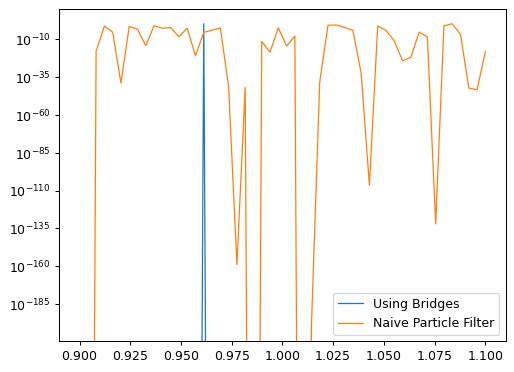

In [26]:
plt.figure(dpi=90)

plt.semilogy(voff_Alpha, lklhd_Alpha, alpha=1, label="Using Bridges", lw=1)
plt.semilogy(voff_, lklhd_, alpha=1, label="Naive Particle Filter", lw=1)

plt.legend()
#plt.ylim([1e-8, 1e1])
plt.show()

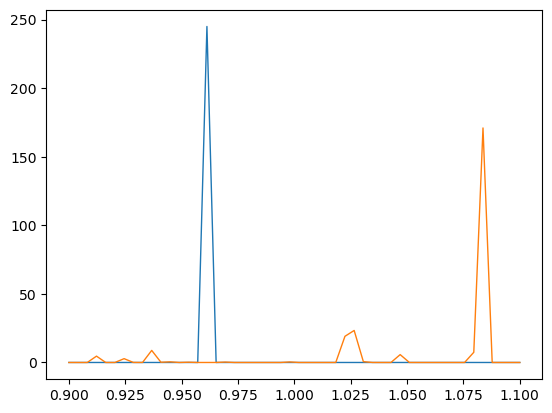

In [27]:
dens_Alpha = lklhd_Alpha
dens_ = lklhd_
plt.plot(voff_Alpha, dens_Alpha / np.trapz(dens_Alpha, voff_Alpha), alpha=1, label="Using Bridges", lw=1)
plt.plot(voff_, dens_ / np.trapz(dens_, voff_), alpha=1, label="Using Bridges", lw=1)
#plt.semilogy(voff_, lklhd_, alpha=1, label="Naive Particle Filter", lw=1)

In [28]:
STOP

NameError: name 'STOP' is not defined

# Transition probabilities

In [ ]:
transition = np.exp(np.subtract.outer(np.log(lklhd_), np.log(lklhd_)))
transition[transition > 0] = 0
print("Transition probability (no bridges):", 1 - np.exp(transition).mean())

transition = np.exp(np.subtract.outer(lklhd_B, lklhd_B))
transition[transition > 1] = 1.0
transition = np.diag(transition, 0)
print("Transition probability (with bridges):", 1 - transition.mean())

In [ ]:
density = lklhd_ / lklhd_.sum()

transition = np.subtract.outer(np.log(lklhd_), np.log(lklhd_))
transition[transition > 0] = 0
transition_no_bridges = np.exp(transition @ density).mean()

In [ ]:
density = lklhd_B / lklhd_B.sum()

transition = np.subtract.outer(np.log(lklhd_B), np.log(lklhd_B))
transition[transition > 0] = 0
transition_with_bridges = np.exp(transition @ density).mean()

In [ ]:
print("Transition probability with bridges:", transition_with_bridges)
print("Transition probability without bridges:", transition_no_bridges)
print("Ratio:", transition_with_bridges / transition_no_bridges)

# Optimize Likelihood

In [ ]:
params['offsetRNG'] = ZeroBasedRNG()
old_logl = -np.inf
writer = SummaryWriter()
steps = 0

In [ ]:
Agent.recording = False
Agent.awaiting_reward = False

#params['offsetRNG'] = ZeroBasedRNG()

X0 = (np.zeros((1000, 3)))
params['RNG'] = crng()



for _ in tqdm(range(10)):
    params['offsetRNG'] = ZeroBasedRNG()
    params['offsetRNG'].reroll(0.2)

    len_test_B = []
    rew_test_B = []
    logl_test_B = []
    
    Alpha_offsets = np.linspace(Alpha_offset_min, Alpha_offset_max, 10)
    
    for Alpha_off in (Alpha_offsets):
            params['sigma_observation'] = relaxation * _SIG_OBS_
            params['logv'] = np.log(_GT_V_)
            params['logAlpha'] = np.log(_GT_ALPHA_ * Alpha_off)
            params['additional_agent_information'] = [Alpha_off, ]
            params['deterministic_agent'] = True
            params['use_bridge_offsets'] = True
            params['RNG'].reroll()
            params['omit_bridges'] = False
            params['bridge_spread_rate'] = 0.
            params['offset_shift_PHI'] = 0.
            params['offset_slope_PHI'] = 0.
            res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
            length = res['trajectory'].shape[1]
            len_test_B.append(length)
            rew_test_B.append([Alpha_off, res['total_reward_collected']])
            logl_test_B.append([Alpha_off, res['logl']])
    
    
    voff_ = np.array(logl_test)[:, 0]
    logl_ = np.array(logl_test)[:, 1]
    
    logl_ -= logl_.max()
    lklhd_ = np.exp(logl_)
    
    voff_B = np.array(logl_test_B)[:, 0]
    logl_B = np.array(logl_test_B)[:, 1]
    
    logl_B -= logl_B.max()
    lklhd_B = np.exp(logl_B)

    label = "Using Bridges" if _==1 else None
    
    plt.semilogy(voff_B, lklhd_B, alpha=1, c='b', label=label, lw=1)
    
plt.semilogy(voff_, lklhd_, alpha=1, c='orange', label="Naive Particle Filter", lw=1)

plt.legend()
plt.ylim([1e-8, 1e2])
plt.show()

# Markov Chain Monte Carlo MCMC

In [ ]:
Agent.recording = False
Agent.awaiting_reward = False

#params['offsetRNG'] = ZeroBasedRNG()

X0 = (np.zeros((N_parts, 3)))
params['RNG'] = crng()
params['offsetRNG'] = ZeroBasedRNG()
params['deterministic_agent'] = True
params['use_bridge_offsets'] = True
params['offset_shift_PHI'] = 0.
params['offset_slope_PHI'] = 0.
params['omit_bridges'] = False
params['bridge_spread_rate'] = 0.

writer = SummaryWriter(flush_secs=10)

N_samples = 10000

sigma_B = 0.1
sigma_agent = 0.01

B_off = 1.0
logl = -np.inf

B_samples = []

n = 0

In [ ]:
proposals_B = 0
proposals_Bridge = 0
accepts_B = 0
accepts_Bridge = 0
ess = 0
ess_refresh_rate = 10
for _ in (pbar := tqdm(range(N_samples))):

    try:

        # B Block

        B_off_proposal =  B_off + np.random.randn() * sigma_B

        prior = (B_off_proposal > 0.) and (B_off_proposal < 2.0)
    
        params['logB'] = np.log(_GT_B_ * B_off_proposal)
        params['additional_agent_information'] = [B_off_proposal, ]
        params['RNG'].reroll() # This we don't revert, we're fully randomizing the bridge transient
        
        res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
        new_logl = res['logl']
        accept = (np.random.rand() < np.exp(new_logl- logl)) and prior
    
        if accept:
            logl = new_logl
            B_off = B_off_proposal
            accepts_B += 1


        proposals_B += 1


        # Bridge Block

        params['offsetRNG'].reroll(sigma_agent)
        params['logB'] = np.log(_GT_B_ * B_off)
        params['additional_agent_information'] = [B_off, ]

        res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
        new_logl = res['logl']
        accept = np.random.rand() < np.exp(new_logl- logl)

        if accept:
            logl = new_logl
            accepts_Bridge += 1
        else:
            params['offsetRNG'].revert()
            
        proposals_Bridge += 1

        B_samples.append(B_off)
        writer.add_scalar("MCMC/B_off", B_off, n)
        n += 1


        if not n % ess_refresh_rate:
            ess = effective_sample_size(B_samples)
            writer.add_scalar("MCMC/ESS", ess, n)

        pbar.set_description(f"Acceptance: B_offset: {100 * accepts_B / proposals_B:.0f}% / Bridge: {100 * accepts_Bridge / proposals_Bridge:.0f}%. ESS: {ess:.1f}")

    
    except KeyboardInterrupt:
        print("Bye!")
        break

plt.hist(B_samples, density=True, bins=int(np.ceil(np.log2(ess)+1)))
lkl_smooth = gaussian_filter1d(lklhd_, 4)
plt.plot(voff_, lkl_smooth / np.trapz(lkl_smooth, voff_), alpha=1, label="Naive Particle Filter", lw=3, c='orange')
plt.show()
plt.plot(B_samples)
plt.show()
